In [2]:
import pandas as pd
import numpy as np
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

# Series

### Selection

##### Series -> Scalar

```py
s.loc['a']      -> scalar   # label-only
s.iloc[2]       -> scalar   # index-only
s[2] or s['a']  -> scalar   # label or index dependent on ...
```

##### Series -> Series

```py
s.loc[['a']]    -> series
s.iloc[[2]]     -> series

s[['a', 'b']]   -> series
s[1:4]          -> series
s[s > 0]        -> series
```

### Unique handling

##### .unique() -> Series

```python
# Return a series of unique values
s.unique()
```

### .values_count() -> Series


```py
Count # occurrences of **each unique value (new label)**
s.value_counts()
```

# Dataframe

### Create a DataFrame

##### Use array (1d or 2d)

- If 2D, just treat each element is row-element

In [4]:
df_list = pd.DataFrame([1, 2, 3], columns=["Numbers"])
df_list

,Numbers
0,1
1,2
2,3


In [5]:
df_list = pd.DataFrame([[1, "one"], [2, "two"]], columns = ["Number", "Description"])
df_list

,Number,Description
0,1,one
1,2,two


##### Use dict

```py
{
    col_name: [col_values, ...]
}
```

In [6]:
df_dict = pd.DataFrame({
    "Fruit": ["Strawberry", "Orange"], 
    "Price": [5.49, 3.99]
})
df_dict

,Fruit,Price
0,Strawberry,5.49
1,Orange,3.99


```py
{
    {col_name1 : col_val1, col_name2 : col_val2},
    ...
}
```

In [7]:
df_dict = pd.DataFrame(
    [
        {"Fruit":"Strawberry", "Price": 5.49}, 
        {"Fruit": "Orange", "Price": 3.99}
    ]
)
df_dict

,Fruit,Price
0,Strawberry,5.49
1,Orange,3.99


##### Use `Series`

In [8]:
# row labels (index =) MUST be the same

s_a = pd.Series(["a1", "a2", "a3"], index = ["r1", "r2", "r3"])
s_b = pd.Series(["b1", "b2", "b3"], index = ["r1", "r2", "r3"])

pd.DataFrame({
    "A-column": s_a, 
    "B-column": s_b
})

,A-column,B-column
r1,a1,b1
r2,a2,b2
r3,a3,b3


In [13]:
pd.DataFrame(s_a) # or s_a.to_frame()

,0
r1,a1
r2,a2
r3,a3


In [14]:
s_a.to_frame()

,0
r1,a1
r2,a2
r3,a3


### .shape vs .size
```py
df.shape -> tuple   # (n_row, n_col)
df.size -> int      # n_row * n_col
```

### Selection

##### Normal

<img src="../_images/df-selection-unconditional.png" style="display: block; margin: 0 auto; width: 75%;">

##### Conditional

```py
babynames[(condition1) & | (condition2)]    # OK
babynames[(condition1) and or (condition2)] # ERROR
```

<img src = "../_images/df-selection-conditional.png" style="display: block; margin: 0 auto; width: 60%;">

### Row Handling

##### Re-index to label

There are 2 ways

In [16]:
# Creating a DataFrame from a CSV file and specifying the index column
pd.read_csv("data.csv", index_col = "Station Name")

,Measurement Timestamp,Air Temperature
Station Name,,
63rd Street Weather Station,01/01/2016 12:00:00 AM,-2.80
Oak Street Weather Station,01/01/2016 12:00:00 AM,-2.30
Foster Weather Station,01/01/2016 12:00:00 AM,-3.67
63rd Street Weather Station,01/01/2016 01:00:00 AM,-3.40
Foster Weather Station,01/01/2016 01:00:00 AM,-4.56
...,...,...
Oak Street Weather Station,12/31/2016 10:00:00 PM,0.40
Foster Weather Station,12/31/2016 10:00:00 PM,-1.06
63rd Street Weather Station,12/31/2016 11:00:00 PM,-1.30


In [21]:
temp_df = pd.read_csv("data.csv")
temp_df.reset_index(inplace = True) # Resetting the index so we can set it again
temp_df.set_index("Station Name", inplace = True)
temp_df

,index,Measurement Timestamp,Air Temperature
Station Name,,,
63rd Street Weather Station,0,01/01/2016 12:00:00 AM,-2.80
Oak Street Weather Station,1,01/01/2016 12:00:00 AM,-2.30
Foster Weather Station,2,01/01/2016 12:00:00 AM,-3.67
63rd Street Weather Station,3,01/01/2016 01:00:00 AM,-3.40
Foster Weather Station,4,01/01/2016 01:00:00 AM,-4.56
...,...,...,...
Oak Street Weather Station,23681,12/31/2016 10:00:00 PM,0.40
Foster Weather Station,23682,12/31/2016 10:00:00 PM,-1.06
63rd Street Weather Station,23683,12/31/2016 11:00:00 PM,-1.30


### Column Handling

##### Add new column(s)

Single column: try vectorized

```py
# Create a Series of the length of each name. 
new_series = df["Name"].str.len() -> Series

# Add a column named "name_lengths" that includes the length of each name
df["name_lengths"] = new_series
```
---
```py
# When new columns are derived from existing ones, calculations using .to_numpy() is the fastest
df['new'] = df['A'].to_numpy() * df['B'].to_numpy()
```

Single column **at specific index location**

```py
# Old columns from [i...] will be right-shifted
df.insert(i, new_col_name, data_series, allow_duplicates = False)
```
- `i`: The insertion index. It must be between 0 and len(columns).
- `new_col_name` (str/hashable): The label or name for the new column.
- `data_series` (scalar/Series/array-like): If a scalar is provided, it will be broadcasted to all rows.
- `allow_duplicates` (bool): Insert a column name already exists will raise a `ValueError`

Multiple columns
```py
# Fastest
df[['new1', 'new2']] = pd.DataFrame(data, index = df.index)
```
---
```py
# Alternative
df = df.assign(Admissionnum=[250, 800], 
               Percentage=['85%', '90%'])
```

##### Apply a function to a column

```py
# First, define a function to count the number of times "dr" or "ea" appear in each name
def dr_ea_count(string):
    return string.count('dr') + string.count('ea')

# Then, use `map` to apply `dr_ea_count` to each name in the "Name" column
df["dr_ea_count"] = df["Name"].map(dr_ea_count)
```

##### Rename column

```py
# Rename “name_lengths” to “Length”
df = df.rename(columns = {"name_lengths" : "Length"})
```

##### Drop
```py
# Drop our new "Length" column from the DataFrame
df = df.drop("Length", axis = "columns")

# Drop row = default
df = df.drop("Length")
```

### Groupby(col_name, as_index = ...)

<img src="../_images/df-groupby.png" style="display: block; margin: 0 auto; width: 40%;">

#### 0/ as_index = False or True ?

- `as_index = True` (default): non-select columns become row labeles of the resulting DataFrame.

- `as_index = False`: Resulting DataFrame uses a standard RangeIndex (starting from 0).

    1. No need `.reset_index()` after `.agg` or `.apply`,

    2. which can save memory by avoiding an extra copy of the data.

#### 1/ .agg() and .apply()

##### .agg()

1. Use either:

- A defined summary statistics function e.g mean, max, ...

- A lambda function that **input = Series** and **output = scalar**

2. Faster than `.apply()`

```py
# "mean", "sum", "min", "max", "first", "last"
grouped_df = df.groupby("Year").agg("max")
# Same thing (simple cases)
grouped_df = df.groupby("Year").mean()
# Custom aggregation w/ a lambda input = Series, return = a scalar
grouped_df = df.groupby("Name").agg(lambda s: np.mean(s))
```
---
Multiple aggregations:

```py
grouped_df = df.groupby("Year").agg(["mean", "max"])
```

##### .apply()

1. Input = DataFrame / Series; Output = anything (DataFrame, Series, Scalar)

2. Slower than `.agg()`

#### 2/ .transform() and .filter()

##### .transform()

Returns **same shape as input DataFrame** (unlike `.agg()`) aka result propagates.

```py id="hxq43c"
df["mean_per_year"] = df.groupby("Year")["Count"].transform("mean")
```

##### .filter(func)

1. `func`: Input = `Dataframe`, Output = `bool`

2. Applies `func` to each group/sub-DataFrame:

    - If `func` -> `True` for a group, then **all rows are preserved**.

    - Else: then **all rows are dropped**.

3. Preserves the original indices of input DataFrame: the column we grouped on does NOT become the index

<img src="../_images/df-groupby-filter.png" style="display: block; margin: 0 auto; width: 40%;">

Iterating over groups

```py id="9tfosk"
for name, group in df.groupby("Name"):
    print(name)
    print(group)
```

#### 2/ Column Specific

1 column -> 1 operation


```py
grouped_df = df.groupby("Name").agg({
    "First Letter": "first",
    "Year": "max"
})
```

---

```py
# We can create new column names after operation
grouped_df = df.groupby("Name").agg(
    max_year = ("Year", "max"),             # new_col = (old_col, operation)
    first_letter=("First Letter", "first")
)
```

1 operation -> subset of columns only (others dropped)


```py
grouped_df = df.groupby("Year")[[col_name, ...]].agg("sum")
```

* `[[col_name, ...]]` = **select column before function**:

    * After `groupby()[[col_name, ...]]` → still a **GroupBy object**

    * Only after `.agg()` / `.apply()` → you get a **DataFrame or Series**

* Without column selection, pandas aggregates all numeric columns by default

* Columns not selected are **dropped**

#### 3/ .get_group()

Returns a single group as a DataFrame

```py
group = df.groupby(col_name).get_group(non_selected_col_name)
```

### Pivot Table = 2-way aggregation (column and row)
<img src="../_images/df-pivot-table.png" style="display: block; margin: 0 auto; width: 40%;">

##### Example: Find total # names for each sex (col) AND for each year (row)

```py
# The `pivot_table` method is used to generate a Pandas pivot table
import numpy as np
df.pivot_table(
    columns = "Sex", index = "Year",
    values = "Count", 
    aggfunc = "sum",
)
```

### Sorting

```python
df.sort_values(
    by = ...,       # col / row label to sort
    axis = ...,     # 0 or 'index', 1 or 'columns' 
    ascending = ...,
    inplace = ...,  # -> None or -> DataFrame
    key = ...       # (optional) MUST BE vectorized e.g `lambda col: col.str.lower())`
)
```

### Sampling
```py
# Sample a single row
df.sample()

# Sample m rows
df.sample(m)
```

# -

# Merge Dataframes

### concat

- concat = “stack or place whole tables together horizontally / vertically”

```py
pd.concat([df1, df2], axis = 'index')   # stack rows
```
- Columns are aligned by column name.
- If one table has a column the other does not have, the missing values become NaN.

```py
pd.concat([df1, df2], axis = 'columns') # stack columns
```
- Rows are aligned by index.
- If one table has an index row the other does not have, the missing values become NaN.

### merge vs join

- merge:

    - Usually use by matching values of a column

    - Can only merge **two DataFrames at a time**
    
    - Can use `pd.merge(df1, df2)` or `df1.merge(df2)`


- join:

    - “match by the index, or using one side’s index”

    - Can join **multiple** DataFrames at once

    - Use join() for high-performance operations when your data is already aligned by index.
    
    - Must use `df1.join(df2)`

In [29]:
import pandas as pd

left = pd.DataFrame({
    "id": [10, 20, 30],
    "name": ["A", "B", "C"]
})

right = pd.DataFrame({
    "id": [10, 30],
    "score": [100, 200]
})

print(f"left =\n{left}")
print()
print(f"right =\n{right}")

left =
   id name
0  10    A
1  20    B
2  30    C

right =
   id  score
0  10    100
1  30    200


In [30]:
# “keep all rows from left, and match rows from right where id is equal”
left.merge(right, on="id", how="left")

,id,name,score
0,10,A,100.0
1,20,B,NaN
2,30,C,200.0


In [31]:
# since `id` column exists in both DataFrame
left.join(right, lsuffix="_left", rsuffix="_right")

,id_left,name,id_right,score
0,10,A,10.0,100.0
1,20,B,30.0,200.0
2,30,C,NaN,NaN


# -

# Visualization

### Data Prepartion

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
n = 300

df = pd.DataFrame({
    "category": np.random.choice(["A", "B", "C"], size=n),
    "group": np.random.choice(["G1", "G2"], size=n),
    "x": np.random.normal(50, 10, size=n),
})

df["y"] = 0.7 * df["x"] + np.random.normal(0, 8, size=n)
df["time"] = pd.date_range("2024-01-01", periods=n, freq="D")

# optional: make values differ a bit by category/group
df.loc[df["category"] == "B", "x"] += 8
df.loc[df["group"] == "G2", "y"] += 5

df.head()

,category,group,x,y,time
0,C,G1,52.269843,50.767914,2024-01-01
1,A,G2,47.290377,34.916277,2024-01-02
2,C,G1,54.462893,40.125549,2024-01-03
3,C,G1,61.362423,49.399579,2024-01-04
4,A,G2,55.014268,24.899174,2024-01-05


### Plot Strategy

![](../_images/data100_plot_choice_decision_tree_centered_narrow_fix7_ultra.png)

### Plot Implementation

##### Shared helper

In [46]:
def prepare_plots(n_row, n_col):
    """ Plot single or all the plots together in a grid """
    fig, ax = plt.subplots(
        n_row, n_col,                       # n_row, n_col
        figsize = (5 * n_col, 4 * n_row),   # figsize = (w, h)
        squeeze = False,                    # enable using ax[r, c] or ax[pos] irregardless of n_row, n_col
        constrained_layout = True           # auto-adjust the spacing inside to avoid overlapping plots
    )
    ax = ax.ravel()                         # (optional) enable using ax[0], ax[1] instead of ax[0, 0], ax[0, 1]
    return fig, ax

##### (Grouped Statistics e.g Mean, Median, Max, Min) Bar Plot
```py
sns.barplot(
    y = ...,        # statistics computed in col ...
    x = ...,        # (optional) group by each separated ..., w/o x = whole data
    estimator = ... # default = mean,
    hue = ...       # (optionl) auto-diff color for each group in 'x'
    palette = ..    # (optional) custom color for 'hue'
)
```

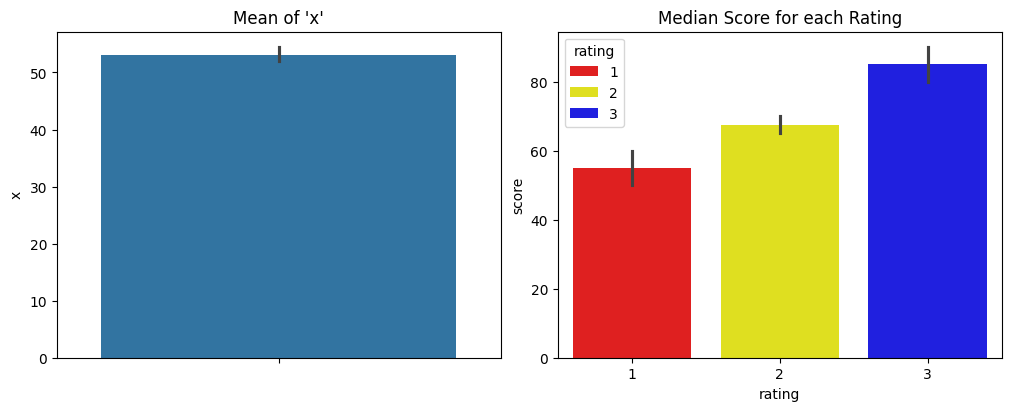

In [74]:
fig, ax = prepare_plots(1, 2)

sns.barplot(data=df, y="x", ax = ax[0])
ax[0].set_title("Mean of 'x'")

df2 = pd.DataFrame({
    "rating": [1, 1, 2, 2, 3, 3, 3],
    "score": [50, 60, 65, 70, 80, 85, 90]
})
sns.barplot(
    data = df2, y = "score", x = "rating",
    estimator = np.median,
    hue = "rating", palette=["red", "yellow", "blue"],
    ax = ax[1]
)
ax[1].set_title("Median Score for each Rating")

plt.show()

##### (Category) Bar (Count), Grouped Bar (Grouped Count)

```py
sns.countplot(...)
```

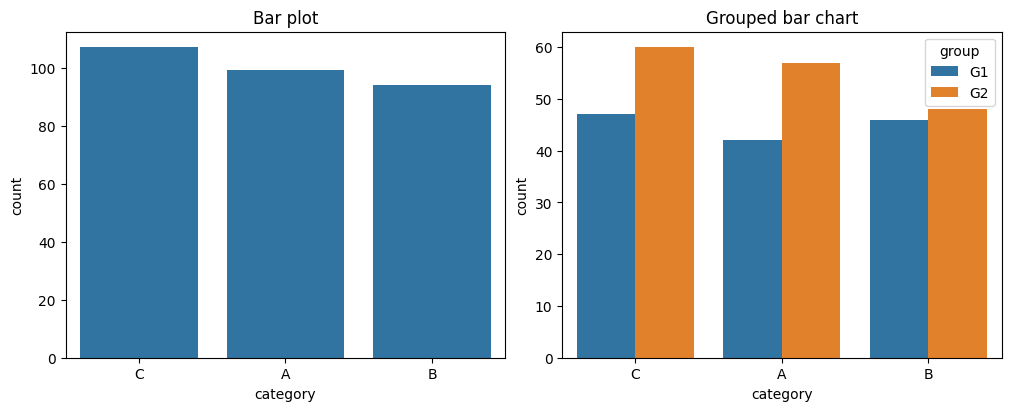

In [ ]:
fig, ax = prepare_plots(1, 2)

# 1 Bar Plot
sns.countplot(
    data=df,
    x="category",   # “count this column, and put its categories on the x-axis”
    ax=ax[0]      # (only when grouping plots) position
)
ax[0].set_title("Bar plot")

# 12 Grouped Bar Chart
sns.countplot(
    data=df, 
    x="category", 
    hue="group", 
    ax=ax[1]
)
ax[1].set_title("Grouped bar chart")

plt.show()

##### Histogram, Overlaid Histogram

```py
sns.histplot(...)
```

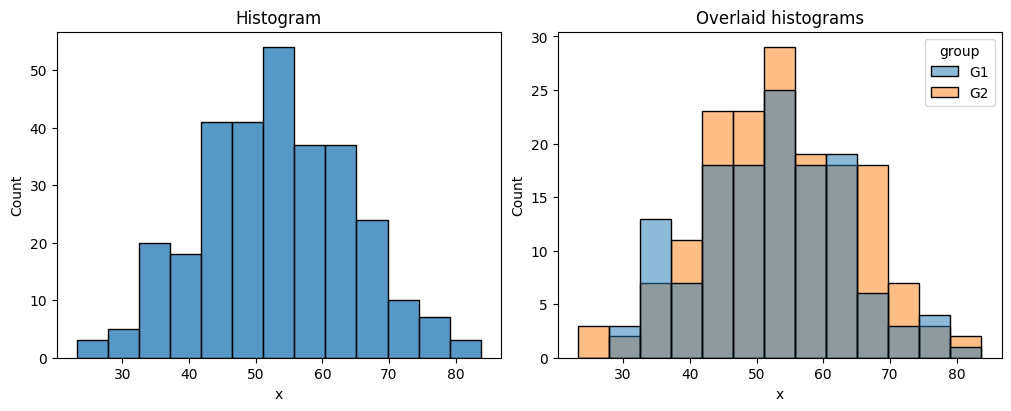

In [49]:
fig, ax = prepare_plots(1, 2)

# 2 Histogram
sns.histplot(data=df, x="x", ax=ax[0])
ax[0].set_title("Histogram")

# 10 Overlaid Histogram
sns.histplot(
    data=df, x="x", 
    hue="group",    # Within col 'x', color separatedly base on categories in col 'group'
    ax=ax[1]
)
ax[1].set_title("Overlaid histograms")

plt.show()

##### Box Plot, Side by Side Box Plot

```py
sns.boxplot(...)

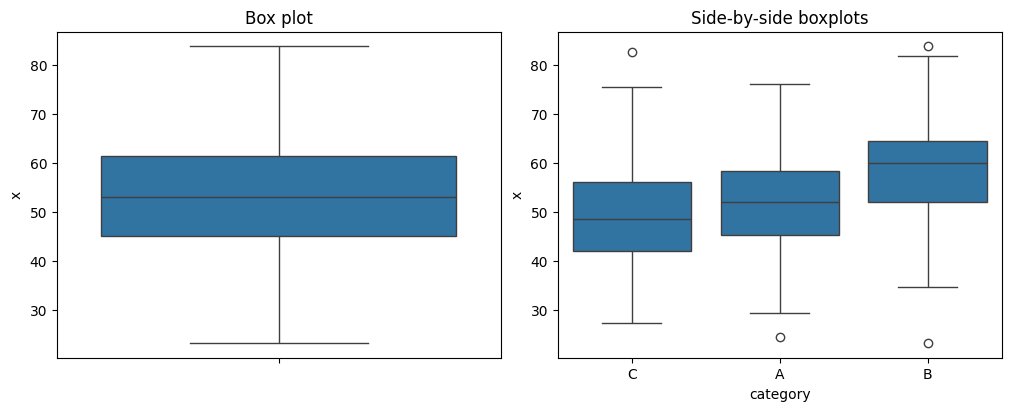

In [54]:
fig, ax = prepare_plots(1, 2)

# 3 Box Plot
sns.boxplot(data=df, y="x", ax=ax[0])   # want vertical view
ax[0].set_title("Box plot")

# 9 Side-by-side boxplot
sns.boxplot(data=df, y="x", x="category", ax=ax[1])
ax[1].set_title("Side-by-side boxplots")

plt.show()

##### Scatter, Line (Time Series)

```py
""" Scatter """
sns.scatterplot(...)

""" Line """
sns.lineplot(...)
ax[...].tick_params(axis = "x", rotation = ...) # avoid x-axis labels overlap -> hard to read
```

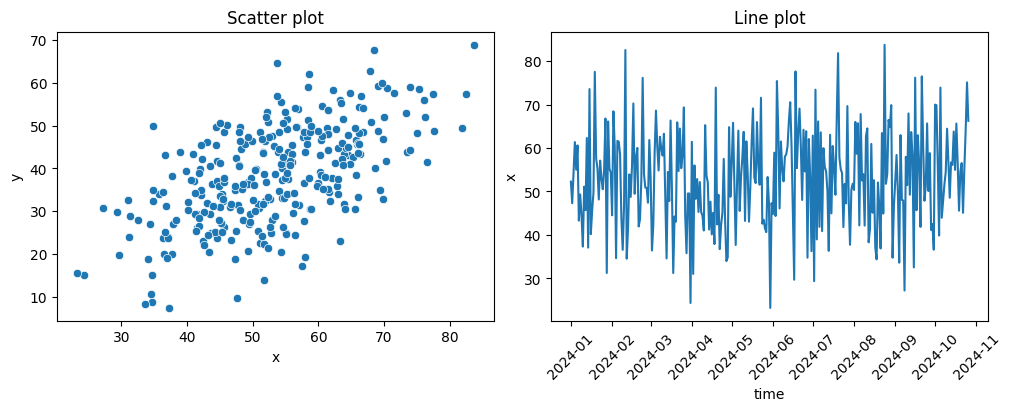

In [67]:
fig, ax = prepare_plots(1, 2)

# 6 Scatter Plot
sns.scatterplot(data=df, x="x", y="y", ax=ax[0])
ax[0].set_title("Scatter plot")

# 11 Line Plot (Time Series)
sns.lineplot(data=df, x="time", y="x", ax=ax[1])
ax[1].tick_params(axis="x", rotation=45)    # avoid x-axis labels overlap -> hard to read
ax[1].set_title("Line plot")

plt.show()

##### Hex, Contour

**Careful: Hex Plot**

* want a standalone seaborn hex plot: → use *Seaborn*
    ```py 
    sns.jointplot(data =, x =, y =, kind = "hex", joint_kws = {"gridsize" : ...})
    ```

* want a hex plot inside existing subplots → use *Matplotlib's ax*
    ```py
    ax[...].hexbin(x =, y =, gridsize =)
    ```

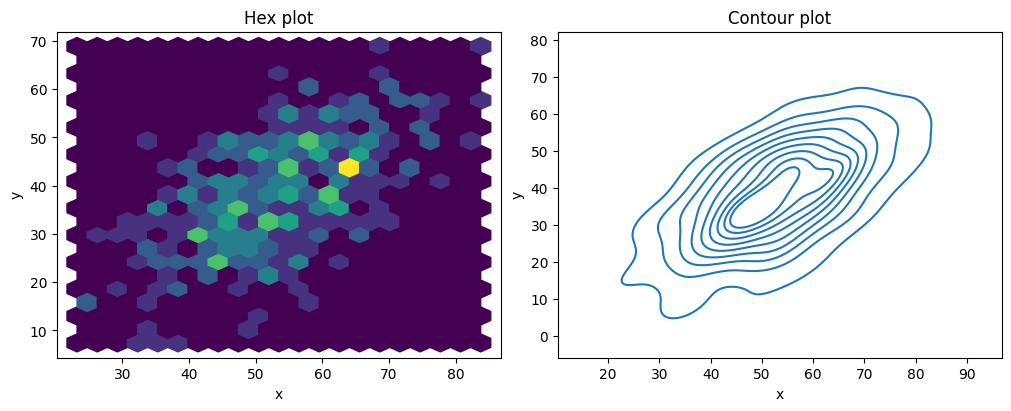

In [63]:
fig, ax = prepare_plots(1, 2)

# 7 Matplotlib's Hex Plot, works seemlessly in subplots with other Seaborn's
ax[0].hexbin(
    x = df["x"], y = df["y"],
    gridsize = 20   # hex in x-axis. Higher n-sample requires Higher gridsize = Smaller bins
)
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[0].set_title("Hex plot")

# 8 Contour Plot
sns.kdeplot(data=df, x="x", y="y", ax=ax[1])
ax[1].set_title("Contour plot")

plt.show()

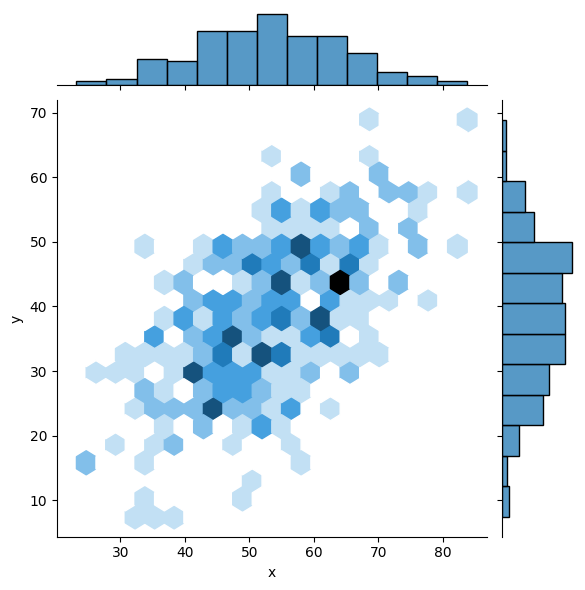

In [65]:
# 7 Seaborn's Hex Plot, MUST STANDALONE
sns.jointplot(
    data = df, x = "x", y = "y",
    kind = "hex",
    joint_kws = {"gridsize": 20},
)
plt.show()

##### KDE, Violin
```py
sns.kdeplot(...)
sns.violinplot(...)
```

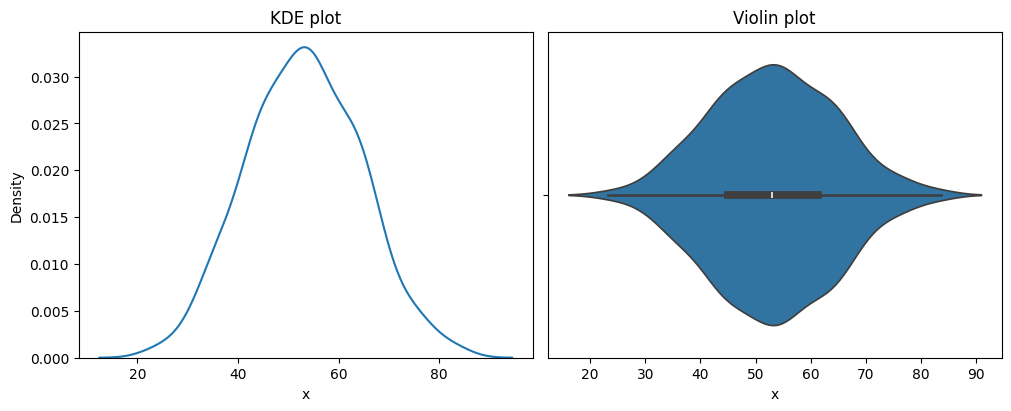

In [62]:
fig, ax = prepare_plots(1, 2)

# 5 KDE Plot
sns.kdeplot(data=df, x="x", ax=ax[0])
ax[0].set_title("KDE plot")

# 4 Violin Plot
sns.violinplot(data=df, x="x", ax=ax[1])
ax[1].set_title("Violin plot")

plt.show()

# -